<div style="background-color: #f5f8fb; border-left: 5px solid #277da8; padding: 16px 20px; margin-bottom: 18px; border-radius: 4px;">
<p style="color: #46586b; font-size: 12px; font-weight: 600; letter-spacing: 1px; margin: 0 0 7px 0;">SIMULACIÓN II</p>
<h1 style="color: #14283f; font-size: 29px; line-height: 1.3; margin: 0;">MODELO SIR CON METROPOLIS-HASTINGS</h1>
</div>

En este trabajo estimo los parámetros de un modelo SIR con **Metropolis-Hastings**. Uso los datos de influenza del artículo [1] y adapto el código de sus referencias. Mi objetivo es describir el brote y representar la incertidumbre de los parámetros bajo los supuestos que elijo.

Primero preparo los datos y el modelo. Después genero cuatro cadenas, resumo los parámetros y comparo el ajuste con las observaciones. Ejecuto las celdas de arriba hacia abajo.

## <span style="color: #277da8;">1. Bibliotecas y datos</span>

Uso **NumPy** para los cálculos, **SciPy** para integrar el SIR, **pandas** para las tablas y **Matplotlib** para las gráficas.

Tomo $N=763$ estudiantes y los 15 valores de la tabla 1 del artículo [1, pp. 1 y 3]. Interpreto $I(t)$ como los **infectados presentes** en cada día. Fijo $I(0)=1$ y adopto $R(0)=0$ del código [2]; así, $S(0)=762$. Uso el día 0 como condición inicial y ajusto los días 1 a 14.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint, ODEintWarning
import warnings
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

N = 763
# Con arange(15) genero los días 0 a 14; el límite 15 queda excluido.
t = np.arange(15, dtype=float)
datos_school = np.array([1, 3, 6, 25, 73, 222, 294, 258,
                         237, 191, 125, 69, 27, 11, 4])
I0, R0 = 1, 0
S0 = N - I0 - R0
y0 = (S0, I0, R0)

datos = pd.DataFrame({"Día": t.astype(int), "Infectados": datos_school})
display(datos.style.hide(axis="index"))

Día,Infectados
0,1
1,3
2,6
3,25
4,73
5,222
6,294
7,258
8,237
9,191


## <span style="color: #277da8;">2. Modelo con el que trabajo</span>

Llamo $S$, $I$ y $R$ al número de susceptibles, infectados y retirados, respectivamente. Conservo las ecuaciones (1)-(3) del artículo [1, p. 2]:

$$\frac{dS}{dt}=-aSI,\qquad
\frac{dI}{dt}=aSI-bI,\qquad
\frac{dR}{dt}=bI.$$

Con $a$ represento la transmisión, en persona$^{-1}$ día$^{-1}$, y con $b$ la remoción, en día$^{-1}$. Supongo una población cerrada, mezcla homogénea y tasas constantes durante los 14 días. Mantengo $S+I+R=N$. Si usara la forma $\beta SI/N$, tendría que convertir $\beta=aN$.

Reutilizo `deriv` y `odeint` de [2]. En `resolver_sir` compruebo que la integración termine correctamente y devuelva valores finitos y físicamente admisibles. Si falla, detengo esa evaluación; durante MCMC rechazo la propuesta.

In [2]:
# Reutilizo las derivadas del repositorio InverseProblem [2].
def deriv(Y, t, N, a, b):
    S, I, R = Y  # Desempaqueto las tres componentes del estado.
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return dSdt, dIdt, dRdt


def resolver_sir(a, b, tiempos=t):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", ODEintWarning)
            solucion, info = odeint(
                deriv, y0, tiempos, args=(N, a, b),
                rtol=1e-8, atol=1e-8, full_output=True)
    except ODEintWarning as aviso:
        raise RuntimeError("La integración del SIR no fue fiable.") from aviso

    if info["message"] != "Integration successful.":
        raise RuntimeError("El integrador no terminó correctamente.")
    if not np.isfinite(solucion).all():
        raise RuntimeError("La solución contiene valores no finitos.")
    if solucion.min() < -1e-6 or not np.allclose(
            solucion.sum(axis=1), N, rtol=0, atol=1e-5):
        raise RuntimeError("La solución incumple los controles poblacionales.")
    return solucion


# Tolero únicamente pequeñas diferencias de redondeo numérico.
prueba = resolver_sir(0.002, 0.4)
assert np.allclose(prueba[0], y0)
assert np.allclose(prueba.sum(axis=1), N, rtol=0, atol=1e-5)
print("Compruebo las condiciones iniciales y la conservación de S + I + R.")

Compruebo las condiciones iniciales y la conservación de S + I + R.


## <span style="color: #277da8;">3. Distribución que voy a muestrear</span>

Adapto `loglike` de [4] y supongo errores normales, independientes y con desviación común $\sigma$:

$$I_j^{\mathrm{obs}}\mid a,b,\sigma\sim
\mathcal N\bigl(I(t_j;a,b),\sigma^2\bigr),\qquad j=1,\ldots,14.$$

Estimo también $\sigma$, en personas. Esta resume la dispersión alrededor de la curva, incluido un posible desajuste del modelo. Como cambia durante el muestreo, incluyo el término $-n\log\sigma$:

$$\log L(a,b,\sigma)=C-n\log\sigma-\frac{1}{2\sigma^2}
\sum_{j=1}^{n}\bigl[I_j^{\mathrm{obs}}-I(t_j;a,b)\bigr]^2,
\qquad n=14.$$

Omito en el código la constante $C=-n\log(2\pi)/2$, que no depende de los parámetros.

Elijo priors uniformes independientes:

$$a\sim U(0,0.01),\qquad b\sim U(0,1),\qquad\sigma\sim U(0,100).$$

Estos límites son **decisiones de mi adaptación**, no mediciones de los autores. Muestreo la posterior $\pi(\theta\mid I^{\mathrm{obs}})\propto L(\theta)p(\theta)$, con $\theta=(a,b,\sigma)$. Dentro de los límites uso log-prior cero; fuera, $-\infty$. Rechazo también cualquier evaluación numérica no finita.

In [3]:
# Adapto loglike y target del ejemplo MCMC [4].
def loglike(theta):
    a, b, sigma = theta
    try:
        I_modelo = resolver_sir(a, b)[:, 1]  # Selecciono la columna de infectados.
    except RuntimeError:
        return -np.inf
    # Con [1:] excluyo el día 0, que ya fija la condición inicial.
    delta = I_modelo[1:] - datos_school[1:]
    return -len(delta) * np.log(sigma) - np.sum((delta / sigma)**2) / 2


def logprior(theta):
    a, b, sigma = theta
    if 0 < a < 0.01 and 0 < b < 1 and 0 < sigma < 100:
        return 0.0
    return -np.inf


def target(lik, prior, theta):
    lp = prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = lik(theta)
    if not np.isfinite(ll):
        return -np.inf
    logp = lp + ll
    return logp if np.isfinite(logp) else -np.inf

## <span style="color: #277da8;">4. Cómo hago la caminata</span>

Adapto `metropolissampler` de [4] y sigo la tabla 7 de [3, p. 64]:

1. **Propongo** un desplazamiento normal desde el estado actual.
2. **Comparo** la posterior propuesta con la actual.
3. **Acepto o rechazo** y guardo el estado resultante.

La propuesta es simétrica. Por eso comparo logaritmos sin calcular el cociente de propuestas:

$$\log U<\min\{0,\log\pi(\theta^*\mid I^{\mathrm{obs}})
-\log\pi(\theta\mid I^{\mathrm{obs}})\},\qquad U\sim U(0,1).$$

<span style="color: #277da8;"><strong>Conservo los estados repetidos cuando rechazo.</strong></span> Si los eliminara, cambiaría las frecuencias de la cadena. `paso` controla el desplazamiento propuesto; es distinto de $\sigma$, que describe la dispersión de las observaciones.

In [4]:
# Adapto metropolissampler de igomezv/IntroMCMC [4] a Python 3.
def metropolissampler(niters, lik, prior, theta, paso, semilla):
    rng = np.random.default_rng(semilla)
    theta = np.array(theta, dtype=float)
    logp = target(lik, prior, theta)
    if not np.isfinite(logp):
        raise ValueError("El punto inicial debe tener posterior finita.")

    accepted = 0
    samples = [theta.copy()]
    for i in range(niters):
        theta_p = theta + paso * rng.normal(size=len(theta))
        logp_p = target(lik, prior, theta_p)

        if np.log(rng.uniform()) < min(0.0, logp_p - logp):
            theta = theta_p
            logp = logp_p
            accepted += 1

        # Guardo una copia del estado, incluso cuando rechazo la propuesta.
        samples.append(theta.copy())

    return np.array(samples), accepted / niters

## <span style="color: #277da8;">5. Ejecuto cuatro cadenas</span>

Elijo cuatro puntos iniciales a mano y fijo una semilla por cadena. **Todo el ajuste lo hago con MCMC.**

| Configuración | Valor |
|---|---:|
| Propuestas por cadena | 20 000 |
| Estados guardados, incluido el inicial | 20 001 |
| Transiciones iniciales que descarto | 10 000 |
| Estados que conservo por cadena | 10 000 |

Con `burn_in + 1` descarto también el estado inicial. El calentamiento ayuda a reducir su influencia, pero no demuestra convergencia.

In [5]:
niters = 20000
burn_in = 10000
paso = np.array([0.00006, 0.025, 3.0])
inicios = [[0.0015, 0.30, 10.0],
           [0.0030, 0.65, 25.0],
           [0.0018, 0.60, 40.0],
           [0.0025, 0.40, 18.0]]
semillas = [101, 202, 303, 404]

cadenas, aceptaciones = [], []
for inicio, semilla in zip(inicios, semillas):
    cadena, tasa = metropolissampler(
        niters, loglike, logprior, inicio, paso, semilla)
    cadenas.append(cadena)
    aceptaciones.append(tasa)

cadenas = np.array(cadenas)
posterior = cadenas[:, burn_in + 1:, :]
print(f"Conservo {posterior.shape[1]} estados por cadena.")
display(pd.DataFrame({"Cadena": np.arange(1, 5),
                      "Aceptación (%)": 100 * np.array(aceptaciones)}).round(1))

Conservo 10000 estados por cadena.


,Cadena,Aceptación (%)
0,1,34.1
1,2,33.6
2,3,33.1
3,4,33.8


## <span style="color: #277da8;">6. Reviso las cadenas</span>

Observo las trazas y marco el final del calentamiento. Después calculo el $\widehat R$ clásico: comparo la variación **entre las medias de las cadenas** con la variación dentro de ellas. Uso sólo los estados conservados y varianzas con `ddof=1`.

También calculo la correlación a un paso: comparo cada estado con el siguiente. Un $\widehat R$ cercano a 1 es favorable, pero no demuestra convergencia ni independencia. Si la correlación es alta, muchos estados consecutivos aportan información similar. Estos diagnósticos son preliminares y no cuantifican por sí solos el error Monte Carlo de los intervalos.

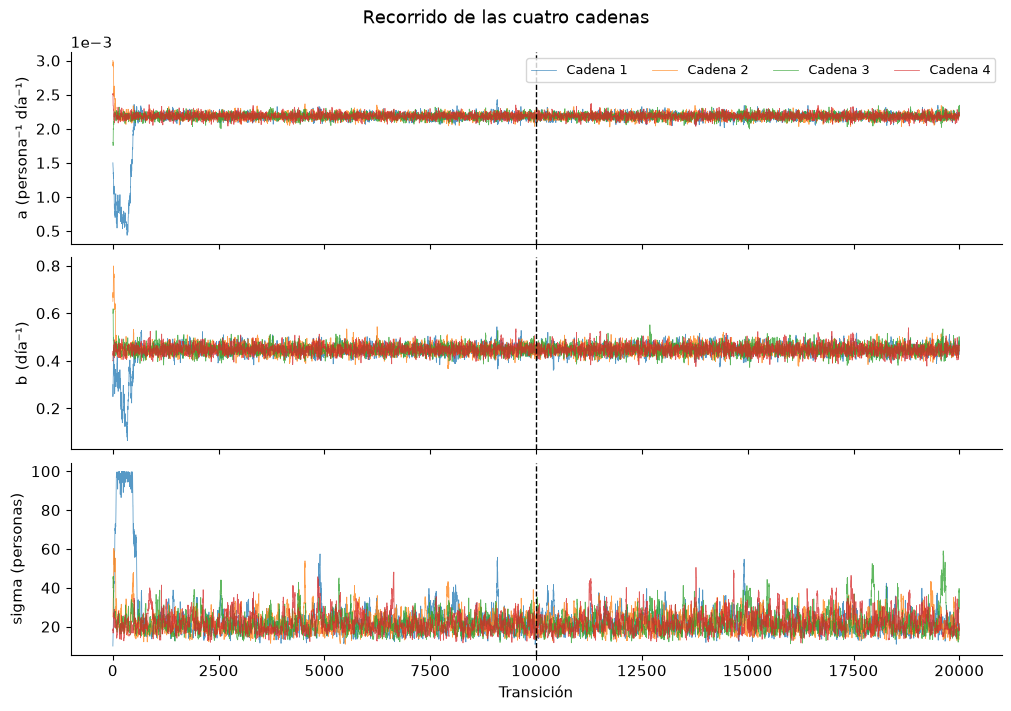

In [6]:
nombres = ["a", "b", "sigma"]
unidades = ["persona⁻¹ día⁻¹", "día⁻¹", "personas"]
etiquetas = [f"{nombre} ({unidad})" for nombre, unidad in zip(nombres, unidades)]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True,
                         layout="constrained")
for j, ax in enumerate(axes):
    for k in range(4):
        ax.plot(cadenas[k, :, j], lw=0.55, alpha=0.75,
                label=f"Cadena {k + 1}")
    ax.axvline(burn_in, color="black", ls="--", lw=1)
    ax.set_ylabel(etiquetas[j])
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[0].legend(ncol=4, fontsize=9)
axes[-1].set_xlabel("Transición")
fig.suptitle("Recorrido de las cuatro cadenas")
plt.show()

In [7]:
# Adapto el diagnóstico del ejemplo [4] a la longitud posterior al descarte.
m, n, d = posterior.shape  # Número de cadenas, estados y parámetros.
medias_cadenas = posterior.mean(axis=1)
W = posterior.var(axis=1, ddof=1).mean(axis=0)
B = n * medias_cadenas.var(axis=0, ddof=1)
Rhat = np.sqrt(((n - 1) / n * W + B / n) / W)

corr_lag1 = np.array([
    [np.corrcoef(c[:-1, j], c[1:, j])[0, 1] for j in range(d)]
    for c in posterior
]).mean(axis=0)

diagnostico = pd.DataFrame({"Parámetro": nombres, "Rhat clásico": Rhat,
                            "Correlación a un paso": corr_lag1})
display(diagnostico.round(4))

,Parámetro,Rhat clásico,Correlación a un paso
0,a,1.0016,0.8012
1,b,1.0009,0.8342
2,sigma,1.0025,0.9523


## <span style="color: #277da8;">7. Resumo los parámetros</span>

Reúno los estados conservados y calculo la **mediana** y los percentiles 2.5 y 97.5. Estos forman un intervalo creíble marginal del 95 %, condicionado a mis supuestos.

Con `reshape(-1, 3)` reúno las cadenas en una tabla de tres columnas: $a$, $b$ y $\sigma$. Uso `axis=0` para calcular los percentiles de cada parámetro. Redondeo sólo la presentación y conservo la precisión interna de los cálculos. Con las medianas de $a$ y $b$ dibujo una curva representativa; no las interpreto como el mínimo exacto del error.

Parámetro,Unidad,Mediana,Percentil 2.5,Percentil 97.5
a,persona⁻¹ día⁻¹,0.002184,0.002105,0.002265
b,día⁻¹,0.447,0.412,0.487
sigma,personas,21,14,35


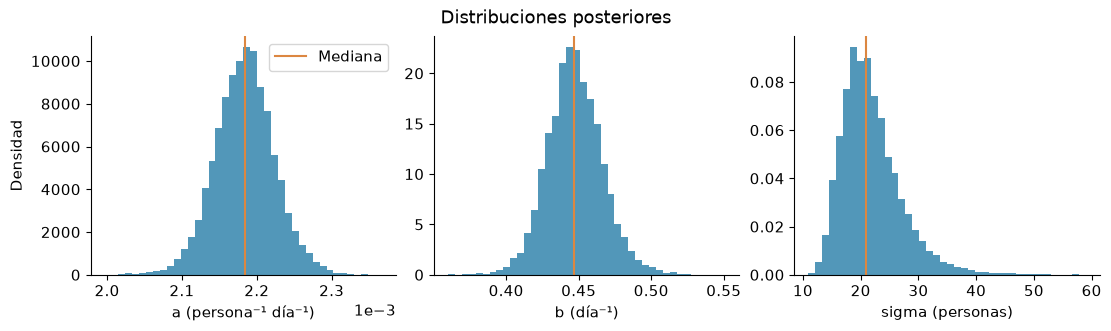

In [8]:
muestras = posterior.reshape(-1, 3)
q025, mediana, q975 = np.quantile(muestras, [0.025, 0.5, 0.975], axis=0)

# Redondeo sólo la tabla; conservo la precisión interna para los cálculos.
decimales = [6, 3, 0]
resumen = pd.DataFrame({
    "Parámetro": nombres,
    "Unidad": unidades,
    "Mediana": [f"{v:.{d}f}" for v, d in zip(mediana, decimales)],
    "Percentil 2.5": [f"{v:.{d}f}" for v, d in zip(q025, decimales)],
    "Percentil 97.5": [f"{v:.{d}f}" for v, d in zip(q975, decimales)]})
display(resumen.style.hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")
for j, ax in enumerate(axes):
    ax.hist(muestras[:, j], bins=40, density=True, color="#277da8", alpha=0.8)
    ax.axvline(mediana[j], color="#dc8741", lw=1.5, label="Mediana")
    ax.set_xlabel(etiquetas[j])
axes[0].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set_ylabel("Densidad")
axes[0].legend()
fig.suptitle("Distribuciones posteriores")
plt.show()

## <span style="color: #277da8;">8. Comparo el ajuste con los datos</span>

Grafico la curva SIR calculada en las medianas. Con 500 estados posteriores obtengo una **banda puntual de trayectoria del 95 %**. Esta representa incertidumbre en la curva y no incluye el ruido de observación $\sigma$.

Calculo el RMSE de los días 1 a 14, en personas. Como uso los mismos datos del ajuste, no lo interpreto como desempeño con datos nuevos.

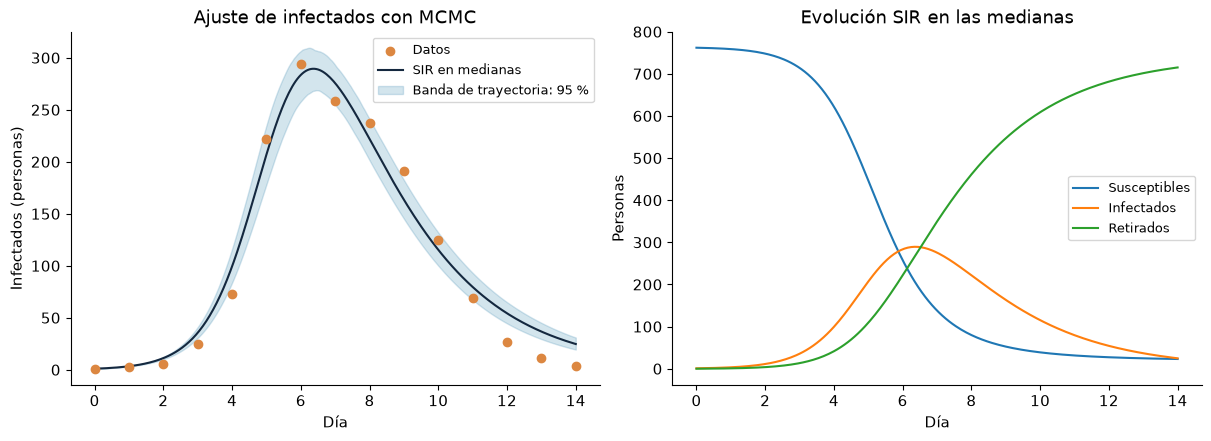

RMSE en los días 1 a 14: 18.0 personas
Máxima diferencia de S+I+R respecto a 763: 4.55e-13


In [9]:
a_est, b_est, sigma_est = mediana
t_fino = np.linspace(0, 14, 281)
solucion = resolver_sir(a_est, b_est, t_fino)

rng_figura = np.random.default_rng(505)
indices = rng_figura.choice(len(muestras), size=500, replace=False)
curvas = np.array([resolver_sir(a, b, t_fino)[:, 1]
                   for a, b, sigma in muestras[indices]])
lim_inf, lim_sup = np.quantile(curvas, [0.025, 0.975], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
axes[0].scatter(t, datos_school, color="#dc8741", label="Datos", zorder=3)
axes[0].plot(t_fino, solucion[:, 1], color="#14283f", label="SIR en medianas")
axes[0].fill_between(t_fino, lim_inf, lim_sup, color="#277da8", alpha=0.2,
                     label="Banda de trayectoria: 95 %")
axes[0].set(title="Ajuste de infectados con MCMC", xlabel="Día",
            ylabel="Infectados (personas)")
axes[0].legend(fontsize=9)

for j, etiqueta in enumerate(["Susceptibles", "Infectados", "Retirados"]):
    axes[1].plot(t_fino, solucion[:, j], label=etiqueta)
axes[1].set(title="Evolución SIR en las medianas", xlabel="Día", ylabel="Personas")
axes[1].legend(fontsize=9)
plt.show()

I_ajustado = resolver_sir(a_est, b_est)[:, 1]
residuos = datos_school[1:] - I_ajustado[1:]
rmse = np.sqrt(np.mean(residuos**2))
error_poblacion = np.max(np.abs(solucion.sum(axis=1) - N))
print(f"RMSE en los días 1 a 14: {rmse:.1f} personas")
print(f"Máxima diferencia de S+I+R respecto a 763: {error_poblacion:.2e}")

## <span style="color: #277da8;">9. Reviso los residuos y simulo observaciones</span>

Calculo los residuos como **observado menos modelo**. Luego tomo 2000 estados posteriores y, para cada uno, simulo los 14 días del ajuste:

$$I_j^{\mathrm{rep}}=I(t_j;a,b)+\sigma Z_j,\qquad Z_j\sim\mathcal N(0,1).$$

Así incluyo el ruido de observación. La banda predictiva es puntual para réplicas de estos días, no una evaluación con datos nuevos. **No recorto los valores negativos**: me permiten ver una limitación de la normal cuando hay pocos infectados.

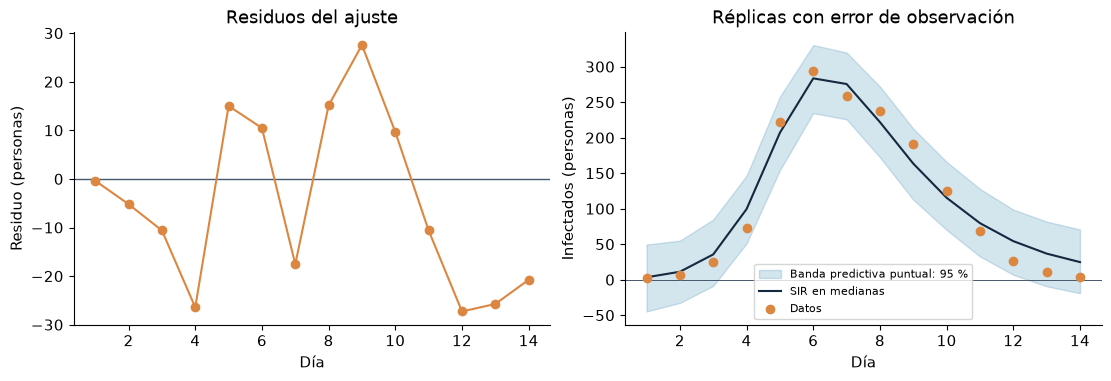

En **70.2 %** de las series replicadas obtengo al menos un valor negativo. Esto muestra que el error normal tiene una limitación importante para representar conteos bajos.

In [10]:
rng_pred = np.random.default_rng(606)
indices_pred = rng_pred.choice(len(muestras), size=2000, replace=False)
parametros_pred = muestras[indices_pred]
medias_pred = np.array([resolver_sir(a, b)[1:, 1]
                        for a, b, sigma in parametros_pred])
# Con [:, 2, None] convierto sigma en una columna: un valor por réplica.
replicas = medias_pred + parametros_pred[:, 2, None] * rng_pred.normal(
    size=medias_pred.shape)
pred_inf, pred_sup = np.quantile(replicas, [0.025, 0.975], axis=0)
fraccion_negativa = np.mean(np.any(replicas < 0, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
axes[0].axhline(0, color="#46586b", lw=1)
axes[0].plot(t[1:], residuos, "o-", color="#dc8741")
axes[0].set(title="Residuos del ajuste", xlabel="Día", ylabel="Residuo (personas)")

axes[1].fill_between(t[1:], pred_inf, pred_sup, color="#277da8", alpha=0.2,
                     label="Banda predictiva puntual: 95 %")
axes[1].plot(t[1:], I_ajustado[1:], color="#14283f", label="SIR en medianas")
axes[1].scatter(t[1:], datos_school[1:], color="#dc8741", label="Datos", zorder=3)
axes[1].axhline(0, color="#46586b", lw=0.7)
axes[1].set(title="Réplicas con error de observación", xlabel="Día",
            ylabel="Infectados (personas)")
axes[1].legend(fontsize=8)
plt.show()

display(Markdown(
    f"En **{100 * fraccion_negativa:.1f} %** de las series replicadas obtengo "
    "al menos un valor negativo. Esto muestra que el error normal tiene "
    "una limitación importante para representar conteos bajos."
))

## <span style="color: #277da8;">10. Resultado y conclusión</span>

Resumo mi estimación con las medianas posteriores y los intervalos de la sección 7. Genero el siguiente párrafo a partir de los valores calculados para mantenerlo consistente con las tablas y las gráficas.

In [11]:
pico = np.argmax(solucion[:, 1])
display(Markdown(
    f"Obtengo medianas de **a = {a_est:.6f}** persona⁻¹ día⁻¹, "
    f"**b = {b_est:.3f}** día⁻¹ y **sigma ≈ {sigma_est:.0f} personas**. "
    f"En la curva representativa encuentro aproximadamente "
    f"**{solucion[pico, 1]:.0f} infectados** en el día **{t_fino[pico]:.2f}**, "
    f"con una malla de 0.05 días. El RMSE del ajuste es "
    f"**{rmse:.1f} personas**. En los días 12 a 14, "
    f"la curva supera los datos en promedio en **{-residuos[-3:].mean():.1f} personas**."
))

Obtengo medianas de **a = 0.002184** persona⁻¹ día⁻¹, **b = 0.447** día⁻¹ y **sigma ≈ 21 personas**. En la curva representativa encuentro aproximadamente **289 infectados** en el día **6.35**, con una malla de 0.05 días. El RMSE del ajuste es **18.0 personas**. En los días 12 a 14, la curva supera los datos en promedio en **24.6 personas**.

**Concluyo que el SIR describe la forma general del brote, pero sobreestima los infectados en los últimos días.** El patrón de los residuos y los valores negativos de las réplicas muestran limitaciones del modelo de observación.

- **Condiciones iniciales.** Fijo $N=763$, $I(0)=1$ y $R(0)=0$; mis intervalos no incluyen incertidumbre sobre estas cantidades.
- **Error normal.** Uso una aproximación continua para datos de conteo. No interpreto este ajuste como un modelo validado para predecir conteos.
- **Priors y muestreo.** Mis resultados dependen de los límites elegidos y de los supuestos del modelo. Los estados de las cadenas están correlacionados; 40 000 estados no equivalen a 40 000 observaciones independientes.

Mis conclusiones se refieren a los datos de la tabla del artículo.

## <span style="color: #277da8;">11. Código que reutilizo y referencias</span>

Identifico las adaptaciones que hago:

| Parte | Origen | Adaptación |
|---|---|---|
| Datos, `deriv` y `odeint` | [2], celdas 11-13 | Uso los días 0 a 14 y compruebo el resultado numérico. |
| `loglike` | [4], celda 9 | Sustituyo la recta por el SIR y estimo $\sigma$. |
| `target` y `metropolissampler` | [4], celdas 10-11 | Incluyo el prior, uso logaritmos y semillas, y rechazo valores no finitos. |
| Diagnóstico clásico | [4], celda 15 | Uso la longitud tras el descarte y varianzas muestrales. |

El artículo [1] ajusta con un algoritmo genético. **Mi ajuste MCMC es una adaptación**: reutilizo sus datos y modelo, junto con el muestreador de [4]. Elijo el error normal y los priors; añado residuos y réplicas para examinar sus consecuencias.

1. Medel Esquivel et al. (2021). *The inverse problem of a dynamical system solved with genetic algorithms*. J. Phys.: Conf. Ser. 1723, 012021. [DOI](https://doi.org/10.1088/1742-6596/1723/1/012021). Consulto población en p. 1, ecuaciones (1)-(3) en p. 2 y tabla 1 en p. 3; uso la numeración impresa.
2. Medetl. *InverseProblem*, [SIR_AG.ipynb](https://github.com/Medetl/InverseProblem/blob/6db98f279be8527c112220d6b57c3902b2190ae1/SIR_AG.ipynb), versión `6db98f2`, citada en [1].
3. Medel Esquivel et al. (2021). *An introduction to Markov Chain Monte Carlo*. BEIO 37(1), 47-74. Consulto la tabla 7 en p. 64, aceptación y diagnóstico en p. 65, y el ejemplo en pp. 66-67 del artículo.
4. Gómez-Vargas. *IntroMCMC*, [EjemploMCMC.ipynb](https://github.com/igomezv/IntroMCMC/blob/29807f91780599392e62c7a2b40c08ec6317e9d3/EjemploMCMC.ipynb), versión `29807f9`, citada en [3].